# Path dependency and Monte Carlo simulations: code development

Options with payoffs that depend on the path taken by the underlying and not only on the value at expiration are said to be path-dependent. In this notebook, we will analyze Monte Carlo Simulation of these options. 

- Options analyzed in this notebook do not have closed-form solutions
- We classify options as weakly or strongly path dependent
- Path dependency is manifest as an extra variable in the option pricing besides $t$ and $S_t$ characterizing the path


In [1]:
import sys
sys.path.append("../src")
import numpy as np

## Weak path dependency 

### American put
American options incorporate early exercise and path dependence but we can still characterize the price by $S_t$ and $t$. However, early excercise makes American options an optimization problem. We will price them following the classic paper by Longstaff-Schwartz  "_Valuing American Options by Simulation: A Simple Least-Squares Approach_", Review of Financial Studies 14(1), 113-147.  


Following Section 1 of the aforementioned paper, let us consider the following paths for an American put with strike price $E=1.10$ and  riskless rate $r=0.06$

||||||
| :-: | :-: | :-: | :-: | :-: |
| Path | $t=0$ | $t=1$ | $t=2$ | $t=3$ |
| 1 | 1.00 | 1.09 | 1.08 | 1.34|
| 2 | 1.00 | 1.16 | 1.26 | 1.54|
| 3 | 1.00 | 1.22 | 1.07 | 1.03|
| 4 | 1.00 | 0.93 | 0.97 | 0.92|
| 5 | 1.00 | 1.11 | 1.56 | 1.52|
| 6 | 1.00 | 0.76 | 0.77 | 0.90|
| 7 | 1.00 | 0.92 | 0.84 | 1.01|
| 8 | 1.00 | 0.88 | 1.22 | 1.34|

Starting at final time $t=3$ we would exercise only for the paths $3,4,6,7$


In [2]:
S0=1
E=1.1
rate=0.06
T=3
n_steps=3
dt=T/n_steps

#### Situation at  $t_3$

In [3]:
paths=np.array([[ 1.00 , 1.09 , 1.08 , 1.34], [1.00 , 1.16 , 1.26 , 1.54], [1.00 , 1.22 , 1.07 , 1.03], [1.00 , 0.93 , 0.97 , 0.92],
                [ 1.00 , 1.11 , 1.56 , 1.52], [ 1.00 , 0.76 , 0.77 , 0.90], [1.00 , 0.92 , 0.84 , 1.01], [ 1.00 , 0.88 , 1.22 , 1.34]
               ])

payoffs_t3= np.max(np.concatenate((E-(paths.T)[-1], np.zeros(8))).reshape(2,8), axis=0)
print("Payoffs are identical to the cashflows if the options were European")
print()
print(payoffs_t3)

Payoffs are identical to the cashflows if the options were European

[0.   0.   0.07 0.18 0.   0.2  0.09 0.  ]


Define a function that computes payoff

In [4]:
def payoff_put(paths, strike_price, m_paths, step):
    res= np.max(np.concatenate((strike_price-(paths.T)[-step], np.zeros(m_paths))).reshape(2,m_paths), axis=0)
    return res

print(payoff_put(paths, E, 8, 1))


[0.   0.   0.07 0.18 0.   0.2  0.09 0.  ]


The decision to exercise is trivial

In [5]:
decision_t3=np.zeros(8) 
pos_true_t3=np.array(payoffs_t3>decision_t3, dtype=int)
print(pos_true_t3)

[0 0 1 1 0 1 1 0]


In [6]:
cashflow_t3=payoffs_t3

#### Now, let us look at $t_2$

In [7]:
payoffs_t2= payoff_put(paths, E, 8, 2) 
non_zero_tuple_t2=np.nonzero(payoffs_t2)

print('payoffs at t2 are ', payoffs_t2)


payoffs at t2 are  [0.02 0.   0.03 0.13 0.   0.33 0.26 0.  ]


Now we use these values to regress the discounted payoffs: $E[Y_{t_2}|X_{t_3}]]=a_0 X_{t_3}^2+a_1 X_{t_3} +a_2$

In [8]:
#Xs
paths_for_regression_t2=(paths.T[-2])[non_zero_tuple_t2]

payoffs_for_regression_t2= cashflow_t3[non_zero_tuple_t2]
#Ys
discounted_payoffs_t2= np.exp(-rate*dt)*payoffs_for_regression_t2

print(paths_for_regression_t2)
print(payoffs_for_regression_t2)
print(discounted_payoffs_t2)

[1.08 1.07 0.97 0.77 0.84]
[0.   0.07 0.18 0.2  0.09]
[0.         0.06592352 0.16951762 0.18835291 0.08475881]


We obtain the coefficients using polyfit

In [9]:
coeffs_t2=np.polyfit(paths_for_regression_t2,discounted_payoffs_t2,2)
#define function with fitted coefficients
def val_time(x, coeffs):
    return np.sum(coeffs*[x**2, x, 1])
print(coeffs_t2)

[-1.81357618  2.98341063 -1.06998766]


In [10]:
continuation_values_t2=np.array([val_time(x, coeffs_t2)  for x in paths_for_regression_t2])
print(payoffs_t2[non_zero_tuple_t2])

print(continuation_values_t2)

[0.02 0.03 0.13 0.33 0.26]
[0.03674056 0.04589834 0.11752682 0.15196921 0.15641792]


Decision making

In [11]:
decision_t2=np.array([val_time(x, coeffs_t2)*(val_time(x, coeffs_t2)>0)  for x in (paths.T[-2])])
pos_true_t2=np.array(payoffs_t2>decision_t2, dtype=int)
cashflow_t2=payoffs_t2*pos_true_t2

print(cashflow_t2)


[0.   0.   0.   0.13 0.   0.33 0.26 0.  ]


Cashflow must be updated

In [12]:
pos_true_t3=(pos_true_t3-pos_true_t2)
cashflow_t3=payoffs_t3*pos_true_t3
print(cashflow_t3)

[0.   0.   0.07 0.   0.   0.   0.   0.  ]


#### Situation at $t=1$

In [13]:
payoffs_t1= payoff_put(paths, E, 8,  3) 
non_zero_tuple_t1=np.nonzero(payoffs_t1)
print('payoffs at t1 are ', payoffs_t1)

payoffs at t1 are  [0.01 0.   0.   0.17 0.   0.34 0.18 0.22]


In [14]:
paths_for_regression_t1=(paths.T[-3])[non_zero_tuple_t1]
payoffs_for_regression_t1= cashflow_t2[non_zero_tuple_t1]
discounted_payoffs_t1= np.exp(-rate*dt)*payoffs_for_regression_t1

print(paths_for_regression_t1)
print(payoffs_for_regression_t1)
print(discounted_payoffs_t1)


[1.09 0.93 0.76 0.92 0.88]
[0.   0.13 0.33 0.26 0.  ]
[0.         0.12242939 0.3107823  0.24485878 0.        ]


In [15]:
coeffs_t1=np.polyfit(paths_for_regression_t1, discounted_payoffs_t1,2)
print(coeffs_t1)

[ 1.35645659 -3.3354434   2.03751234]


In [16]:
continuation_values_t1=np.array([val_time(x, coeffs_t1)  for x in paths_for_regression_t1])
print(payoffs_t1[non_zero_tuple_t1])
print(continuation_values_t1)

[0.01 0.17 0.34 0.18 0.22]
[0.01348511 0.10874928 0.28606468 0.11700927 0.15276213]


Decision $t_1$

In [17]:
decision_t1=np.array([val_time(x, coeffs_t1)*(val_time(x, coeffs_t1)>0)  for x in (paths.T[-3])])
pos_true_t1=np.array(payoffs_t1>decision_t1, dtype=int)
cashflow_t1=payoffs_t1*pos_true_t1
print(cashflow_t1)

[0.   0.   0.   0.17 0.   0.34 0.18 0.22]


In [18]:
#update pos_true
pos_true_t2=np.array((pos_true_t2-pos_true_t1)>0, dtype=int) 

In [19]:
cashflow_t2=payoffs_t2*pos_true_t2

In [20]:
pos_true=np.array([pos_true_t1, pos_true_t2, pos_true_t3])
print(pos_true.T)

[[0 0 0]
 [0 0 0]
 [0 0 1]
 [1 0 0]
 [0 0 0]
 [1 0 0]
 [1 0 0]
 [1 0 0]]


In [21]:
cashflow=np.array([cashflow_t1,cashflow_t2,cashflow_t3])
print(cashflow.T)

[[0.   0.   0.  ]
 [0.   0.   0.  ]
 [0.   0.   0.07]
 [0.17 0.   0.  ]
 [0.   0.   0.  ]
 [0.34 0.   0.  ]
 [0.18 0.   0.  ]
 [0.22 0.   0.  ]]


In [22]:
discounted_cashflow=[cashflow_t1*np.exp(-rate*dt),cashflow_t2*np.exp(-2*rate*dt),cashflow_t3*np.exp(-3*rate*dt)]
print(discounted_cashflow)

[array([0.        , 0.        , 0.        , 0.16009997, 0.        ,
       0.32019994, 0.16951762, 0.2071882 ]), array([0., 0., 0., 0., 0., 0., 0., 0.]), array([0.        , 0.        , 0.05846891, 0.        , 0.        ,
       0.        , 0.        , 0.        ])]


In [23]:
price=np.sum([np.mean(path) for path in discounted_cashflow])

print('The price of American Put is ', price)
print()
print('Reproduces value of section 1 of LSM paper')

The price of American Put is  0.11443433004505697

Reproduces value of section 1 of LSM paper


### Functions to implement above derivation

In [24]:
# We import the path generator
from geometric_brownian_motion import generate_GBM_paths

In [25]:
# We set initial values those of LSM paper to check pricing
paths= paths

def polynomial_for_reg(x, deg):
    return np.vstack([x**k for k in range(deg+1)]).T
    

def american_put_LSM_preliminary(paths, S0=1, strike_price=1.1, rate=0.06, volatility=0.5, t_exercise=3, 
                                 n_steps=3, seed=91873098, deg=2):
    dt = t_exercise / n_steps
    #check without optimization of antithetic variables
    S=paths 
    # Compare prices at once at time=t_exercise
    payoff=np.maximum(strike_price-S[:,-1], 0.0)
    #create auxiliary array to fill for decision making
    decisions=np.zeros_like(S, dtype=bool)
    #decision at t_exercise is trivial
    decisions[:,-1]=payoff>0

    #start of the iteration in decreasing steps
    for n in range(n_steps, 0,-1):
        payoff=payoff*np.exp(-rate*dt)
        in_the_money=np.where(S[:,n]<strike_price)[0]
        if len(in_the_money)==0:
            continue
        #Regression step
        X=polynomial_for_reg(S[in_the_money, n], deg)
        Y=payoff[in_the_money]
        coeff, *_=np.linalg.lstsq(X,Y,rcond=None)
        continuation=X @ coeff
        #decisions at each step
        exercise_now=np.maximum(strike_price-S[in_the_money, n], 0.0)
        exercise_idx=in_the_money[continuation < exercise_now]
        payoff[exercise_idx]=exercise_now[continuation<exercise_now]
        #update decision table
        decisions[exercise_idx, :]=False
        decisions[exercise_idx, n]=True   
    #We discount the value from t_1 to 0 
    price= payoff.mean()*np.exp(-rate*dt)
    return price

print(american_put_LSM_preliminary(paths), 'matches the original paper')


0.11443433004505696 matches the original paper


In [26]:
#Let us test the preliminary function 
volatility=0.4
set_of_paths= [8, 64, 256, 1024, 5000, 10_000, 50_000, 100_000]
generated_paths=[generate_GBM_paths(S0=S0, rate=rate, volatility=volatility, m_paths=kpaths, n_steps=252, antithetic=False) for kpaths in set_of_paths]

prices=[american_put_LSM_preliminary(testpath, S0=S0, strike_price=E, rate=rate, volatility=volatility, t_exercise=1, 
                                 n_steps=252, seed=91873098, deg=2) for testpath in generated_paths]


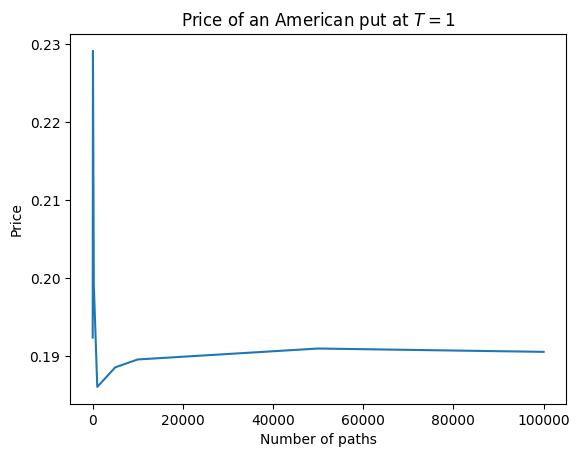

In [27]:
import matplotlib.pyplot as plt
plt.title('Price of an American put at $T=1$')
plt.plot(set_of_paths, prices)
plt.xlabel('Number of paths')
plt.ylabel('Price')
plt.show()

In [28]:
# Let us repeat the exercise with antithetic variables

#Let us test the preliminary function 
volatility=0.4
set_of_paths= [8, 64, 256, 1024, 5000, 10_000, 50_000]
generated_paths=[generate_GBM_paths(S0=S0, rate=rate, volatility=volatility, m_paths=kpaths, n_steps=252, antithetic=True) for kpaths in set_of_paths]

prices=[american_put_LSM_preliminary(testpath, S0=S0, strike_price=E, rate=rate, volatility=volatility, t_exercise=1, 
                                 n_steps=252, seed=91873098, deg=2) for testpath in generated_paths]


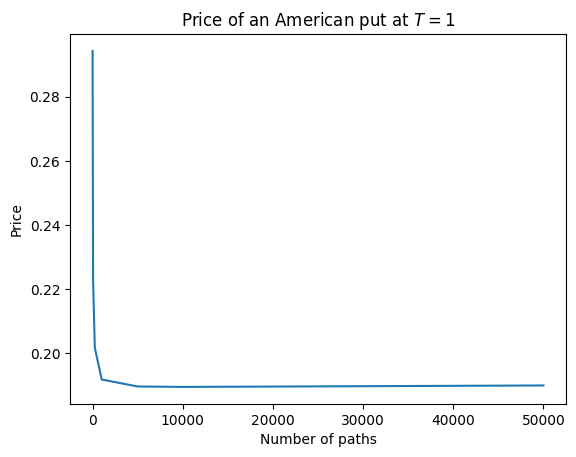

In [29]:
import matplotlib.pyplot as plt
plt.title('Price of an American put at $T=1$')
plt.plot(set_of_paths, prices)
plt.xlabel('Number of paths')
plt.ylabel('Price')
plt.show()

In [30]:
# Let us repeat the exercise with degree 3

#Let us test the preliminary function 
volatility=0.4
set_of_paths= [8, 64, 256, 1024, 5000, 10_000, 50_000]
generated_paths=[generate_GBM_paths(S0=S0, rate=rate, volatility=volatility, m_paths=kpaths, n_steps=252, antithetic=True) for kpaths in set_of_paths]

prices=[american_put_LSM_preliminary(testpath, S0=S0, strike_price=E, rate=rate, volatility=volatility, t_exercise=1, 
                                 n_steps=252, seed=91873098, deg=3) for testpath in generated_paths]



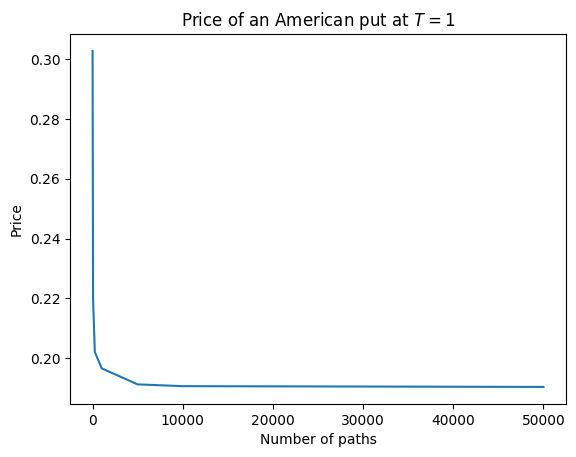

In [31]:
import matplotlib.pyplot as plt
plt.title('Price of an American put at $T=1$')
plt.plot(set_of_paths, prices)
plt.xlabel('Number of paths')
plt.ylabel('Price')
plt.show()

### Final form of functions for American put

In [32]:
#We leave this as free function 
def regression_function(x, deg):
    return np.vstack([x**k for k in range(deg+1)]).T
    

def american_put_LSM(S0=1, strike_price=1.1, rate=0.06, volatility=0.5, m_paths=8, t_exercise=3, 
                                 n_steps=3, seed=91873098, deg=2):
    dt = t_exercise/n_steps
    #with antithetic variables
    S=generate_GBM_paths(S0=S0, rate=rate, volatility=volatility, m_paths=m_paths, n_steps=n_steps, antithetic=True) 
    # Compare prices at once at time=t_exercise
    payoff=np.maximum(strike_price-S[:,-1], 0.0)
    #create auxiliary array to fill for decision making
    decisions=np.zeros_like(S, dtype=bool)
    #decision at t_exercise is trivial
    decisions[:,-1]=payoff>0

    #start of the iteration in decreasing steps
    for n in range(n_steps, 0,-1):
        payoff=payoff*np.exp(-rate*dt)
        in_the_money=np.where(S[:,n]<strike_price)[0]
        if len(in_the_money)==0:
            continue
        #Regression step
        X=regression_function(S[in_the_money, n], deg)
        Y=payoff[in_the_money]
        coeff, *_=np.linalg.lstsq(X,Y,rcond=None)
        continuation=X @ coeff
        #decisions at each step
        exercise_now=np.maximum(strike_price-S[in_the_money, n], 0.0)
        exercise_idx=in_the_money[continuation < exercise_now]
        payoff[exercise_idx]=exercise_now[continuation<exercise_now]
        #update decision table
        decisions[exercise_idx, :]=False
        decisions[exercise_idx, n]=True   
    #We discount the value from t_1 to 0 
    price= payoff.mean()*np.exp(-rate*dt)
    return price

american_put_LSM()

np.float64(0.22730990857972422)

In [33]:
prices=[american_put_LSM(m_paths=mpaths, rate=rate, volatility=volatility, strike_price=E, t_exercise=1, 
                                 n_steps=252, seed=91873098, deg=3) for mpaths in set_of_paths]

In [34]:
#compare against the vanilla put
from vanilla_options import bs_put

price_vanilla_put=bs_put(S0=S0, K=E, r=rate, sigma=volatility, T=1)

In [35]:
#Let us compare against the Vanilla put
print(prices[-1])
print(price_vanilla_put)
print('prices of American options are higher than their corresponding vanillas')

0.19032669864742482
0.17995849782126178
prices of American options are higher than their corresponding vanillas


## Strong path dependency 

### Floating-strike Asian call option
The payoff of this options reads

$$
G(\{S_t\})= \max(S_T-A_T, 0), \quad  A_T= \frac 1 N \sum_{k=1}^N S_{t_k} \, ,
$$
where  $A_T$ is the arithmetic average over the $N$ fixing dates $t_1, t_2, \dots, t_N$. The option does not only depend on the path taken by the underlying but also on the average $A_T$. 


In [36]:
from geometric_brownian_motion import generate_GBM_paths

In [37]:
?generate_GBM_paths

Signature:
generate_GBM_paths(
    S0=1,
    rate=0.06,
    volatility=0.5,
    m_paths=2,
    t_exercise=1,
    n_steps=252,
    seed=918723098,
    antithetic=True,
)
Docstring: Function to generate random paths, requires numpy to run. Uses exact solution  
File:      ~/PycharmProjects/derivatives_pricing/src/geometric_brownian_motion.py
Type:      function

In [41]:
#We use the simulation of the GBM to smulate the paths

import numpy as np

#define the parameters of the walk
T=1
volatility=0.5
n_steps=252
dt=T/n_steps
rate=0.06
S0=1
seed=91873098

#number of paths
m_paths=150 

S2=generate_GBM_paths(
    S0=S0,
    rate=rate,
    volatility=volatility,
    m_paths=m_paths,
    t_exercise=1,
    n_steps=252,
    seed=seed,
    antithetic=False,
)

#Aritmethic average
A_T=S2.mean(axis=1) 

# pricing

payoff=np.maximum(S2[:,-1]-A_T, 0.0)
price_asian= np.exp(-rate*T)*payoff.mean()
error=np.exp(-rate*T)*payoff.std(ddof=1)/np.sqrt(m_paths)

print(price_asian)

0.1472347602837378


It is interesting to compare an Asian call option against a Vanilla put: Asians are usually cheaper

In [42]:
from vanilla_options import bs_put

In [45]:
price_bs_put=bs_put(S0, S0, rate, volatility, T)

In [47]:
print(f'The price of an Asian call is {price}')
print(f'the price of an vanilla call option (At the Money) is {price_bs_put}')


The price of an Asian call is 0.11443433004505697
the price of an vanilla call option (At the Money) is 0.16389605705487997


###  Floating-strike Asian put option with early exercise: Americanized Asian

Now, we will americanize the asian put introducing early exercise

In [48]:
import numpy as np
from scipy.stats import norm

In [49]:
#same parameters
t_exercise=1
volatility=0.5
n_steps=252
dt=T/n_steps
rate=0.06
S0=1
m_paths=150
seed=91873098
strike_price=1.1

In [50]:
# We generate paths as in usual American and Asian
S=generate_GBM_paths(
    S0=S0,
    rate=rate,
    volatility=volatility,
    m_paths=m_paths,
    t_exercise=t_exercise,
    n_steps=n_steps,
    seed=seed,
    antithetic=False,
)
deg=3

# Regression function is now a polynomial basis in two variables: here is where the strong path dependence enters 
# For simplicity I will assume only a second order approximation

def regression_2_vars(x, a, deg=None): 
    return np.vstack([np.ones_like(x), x, x**2, a, a**2, x*a]).T


#Running arithmetic average A_{t_n} = (1/(n+1)) * sum_{k=0..n} S_{t_k}
#(includes t_0 = S_0 in the average)
cumsum_S = np.cumsum(S, axis=1)
A  = cumsum_S / np.arange(1, n_steps + 2)             # (m_paths, n_steps+1)


# Exercise payoff at each t_n: max(K - A_{t_n}, 0) for a put on the average
exercise_payoff = np.maximum(strike_price - A, 0.0)      # (m_paths, n_steps+1)

# Backward induction: starting payoff is the one at t_{n_steps}
payoff = exercise_payoff[:, -1].copy()

# backward in time 
for n in range(n_steps - 1, 0, -1):
    payoff=payoff*np.exp(-rate*dt)
    in_the_money = np.where(A[:, n] < strike_price)[0]   # ITM for a put: A < strike_price
    if len(in_the_money) == 0:
        continue
    X      = regression_2_vars(S[in_the_money, n], A[in_the_money, n])
    Y      = payoff[in_the_money]
    coef, *_ = np.linalg.lstsq(X, Y, rcond=None)
    continuation   = X @ coef
    ex_now = exercise_payoff[in_the_money, n]
    ex_mask = continuation < ex_now
    payoff[in_the_money[ex_mask]] = ex_now[ex_mask]

price_am_asian = payoff.mean()*np.exp(-rate*dt)

In [51]:
price_vanilla_am=american_put_LSM_preliminary(S, S0=S0, strike_price=strike_price, rate=rate, volatility=volatility, t_exercise=t_exercise, 
                                 n_steps=252, seed=seed, deg=2)

In [52]:
print(price_vanilla_am)

0.20336680197352552


### Final form of strong path dependent functions

In [53]:
# Arithmetic Asian
def arithmethic_asian(S0=1, rate=0.06, volatility=0.5, m_paths=150, t_exercise=1, n_steps=252, seed=91873098):
    import numpy as np
    S=generate_GBM_paths(S0=S0, rate=rate, volatility=volatility, m_paths=m_paths,
    t_exercise=t_exercise,    n_steps=n_steps,    seed=seed,
    #We always use antithetic variables    
    antithetic=True)
    #Aritmethic average
    A_T=S.mean(axis=1) 
    
    # pricing
    payoff=np.maximum(S[:,-1]-A_T, 0.0)
    price_asian= np.exp(-rate*t_exercise)*payoff.mean()
    return price_asian    

def americanized_asian(S0=1, rate=0.06, volatility=0.5, m_paths=150, t_exercise=1, n_steps=252, seed=91873098, deg=None):
        
    # Regression function is now a polynomial basis in two variables: here is where the strong path dependence enters 
    # For simplicity I will assume only a second order approximation
    
    def regression_2_vars(x, a, deg=None): 
        return np.vstack([np.ones_like(x), x, x**2, a, a**2, x*a]).T
    
    
    #Running arithmetic average A_{t_n} = (1/(n+1)) * sum_{k=0..n} S_{t_k}
    #(includes t_0 = S_0 in the average)
    cumsum_S = np.cumsum(S, axis=1)
    A  = cumsum_S / np.arange(1, n_steps + 2)             # (m_paths, n_steps+1)
    
    
    # Exercise payoff at each t_n: max(K - A_{t_n}, 0) for a put on the average
    exercise_payoff = np.maximum(strike_price - A, 0.0)      # (m_paths, n_steps+1)
    
    # Backward induction: starting payoff is the one at t_{n_steps}
    payoff = exercise_payoff[:, -1].copy()
    
    # backward in time 
    for n in range(n_steps - 1, 0, -1):
        payoff=payoff*np.exp(-rate*dt)
        in_the_money = np.where(A[:, n] < strike_price)[0]   # ITM for a put: A < strike_price
        if len(in_the_money) == 0:
            continue
        X      = regression_2_vars(S[in_the_money, n], A[in_the_money, n])
        Y      = payoff[in_the_money]
        coef, *_ = np.linalg.lstsq(X, Y, rcond=None)
        continuation   = X @ coef
        ex_now = exercise_payoff[in_the_money, n]
        ex_mask = continuation < ex_now
        payoff[in_the_money[ex_mask]] = ex_now[ex_mask]
    
    price_am_asian = payoff.mean()*np.exp(-rate*dt)
    return price_am_asian

americanized_asian()
    
    


np.float64(0.15604605706696495)